# Querying a 92 GB simulation set without downloading it

The Amaro Lab publishes full-length p53 simulations as a 68 GB archive — and also,
file by file, on a server that honours HTTP range requests. That second detail is
what this notebook is about.

Nine trajectories, 10 GB each: wild type p53 against two hotspot cancer mutants,
**G245S** and **Y220C**, three replicas per condition, 7.5 microseconds each.
Together they are 92 GB, which does not fit in this pod and would take hours to
fetch if it did.

ARGUS answers the questions below by reading **only the frames it needs**, straight
out of the remote files. Watch the megabytes it reports against the 92 GB it is
reading from.

In [ ]:
%reset

In [4]:
%%skill
https://github.com/klinucsd/sage_skills/tree/main/structural-biology/p53-dynamics

## 1. What is in the collection, and what would it cost to look?

Everything came from the catalogue in one clean run. Here is the full picture.

## What's in the collection

The **fl_p53_Anton** dataset (Amaro Lab, UC San Diego — *"Dynamic Profile of DNA-bound Full-length p53 Tetramer"*) holds **nine Anton simulations** of the full-length, DNA-bound p53 tetramer, published file-by-file so any frame can be range-read in place:

| Condition | Replicas | Length each | Frames each | Atoms | One DCD | Whole condition |
| --- | --- | --- | --- | --- | --- | --- |
| wild type | 3 (sim1–sim3) | 7.5 µs | 31,250 @ 240 ps | 27,313 | 10.245 GB | 30.73 GB |
| G245S cancer mutant | 3 (sim1–sim3) | 7.5 µs | 31,250 @ 240 ps | 27,329 | 10.251 GB | 30.75 GB |
| Y220C cancer mutant | 3 (sim1–sim3) | 7.5 µs | 31,250 @ 240 ps | 27,273 | 10.230 GB | 30.69 GB |

Details worth knowing:

- **Design** : 3 conditions × 3 replicas = 67.5 µs of aggregate simulated time (281,250 frames total), all trajectories pre-aligned on the DNA-binding-domain backbones with solvent stripped.
- **Total trajectory data** : 92.18 GB across the nine DCDs (85.9 GiB).
- **Atom counts differ between conditions** (G245S is +16 atoms vs WT, Y220C is −40) because the mutations change composition — comparisons must go by residue number, never atom index.
- Each condition also has its own topology (~2.6 MB PSF each, 7.8 MB for all three), and the lab published small derived PDBs (9 last frames, 18 PCA extremes) for end-state questions.
- The site also offers a single **68.5 GB tarball** — it exists only to be avoided; every file inside it is individually addressable.

## Cost of measuring across all nine: query vs download

A single frame moves ~327–328 KB (one range request), so measuring something over the full length of all nine trajectories costs:

| Approach | Bytes moved | Time (~60 ms/frame) |
| --- | --- | --- |
| **Range-read ~200 frames per replica** (2,314 ns stride) | 0.60 GB (0.59 GB frames + 8 MB topologies) | ~1.8 min |
| **Range-read ~400 frames per replica** (skill's default budget) | 1.19 GB | ~3.6 min |
| **Download all 9 DCD files** | 92.18 GB | hours |
| **Download the tarball** | 68.52 GB | hours, and redundant |

A 200-frame survey of all nine trajectories moves **0.60 GB — 155× less than downloading the nine DCDs** and **116× less than the tarball** ; at the skill's 400-frame budget it is 1.19 GB, still **78× less** . That is the entire point of this collection: a cross-condition measurement over all nine 10-GB trajectories costs about a minute and under a gigabyte, while a download-first approach would spend ~92 GB before the first frame was analyzed.


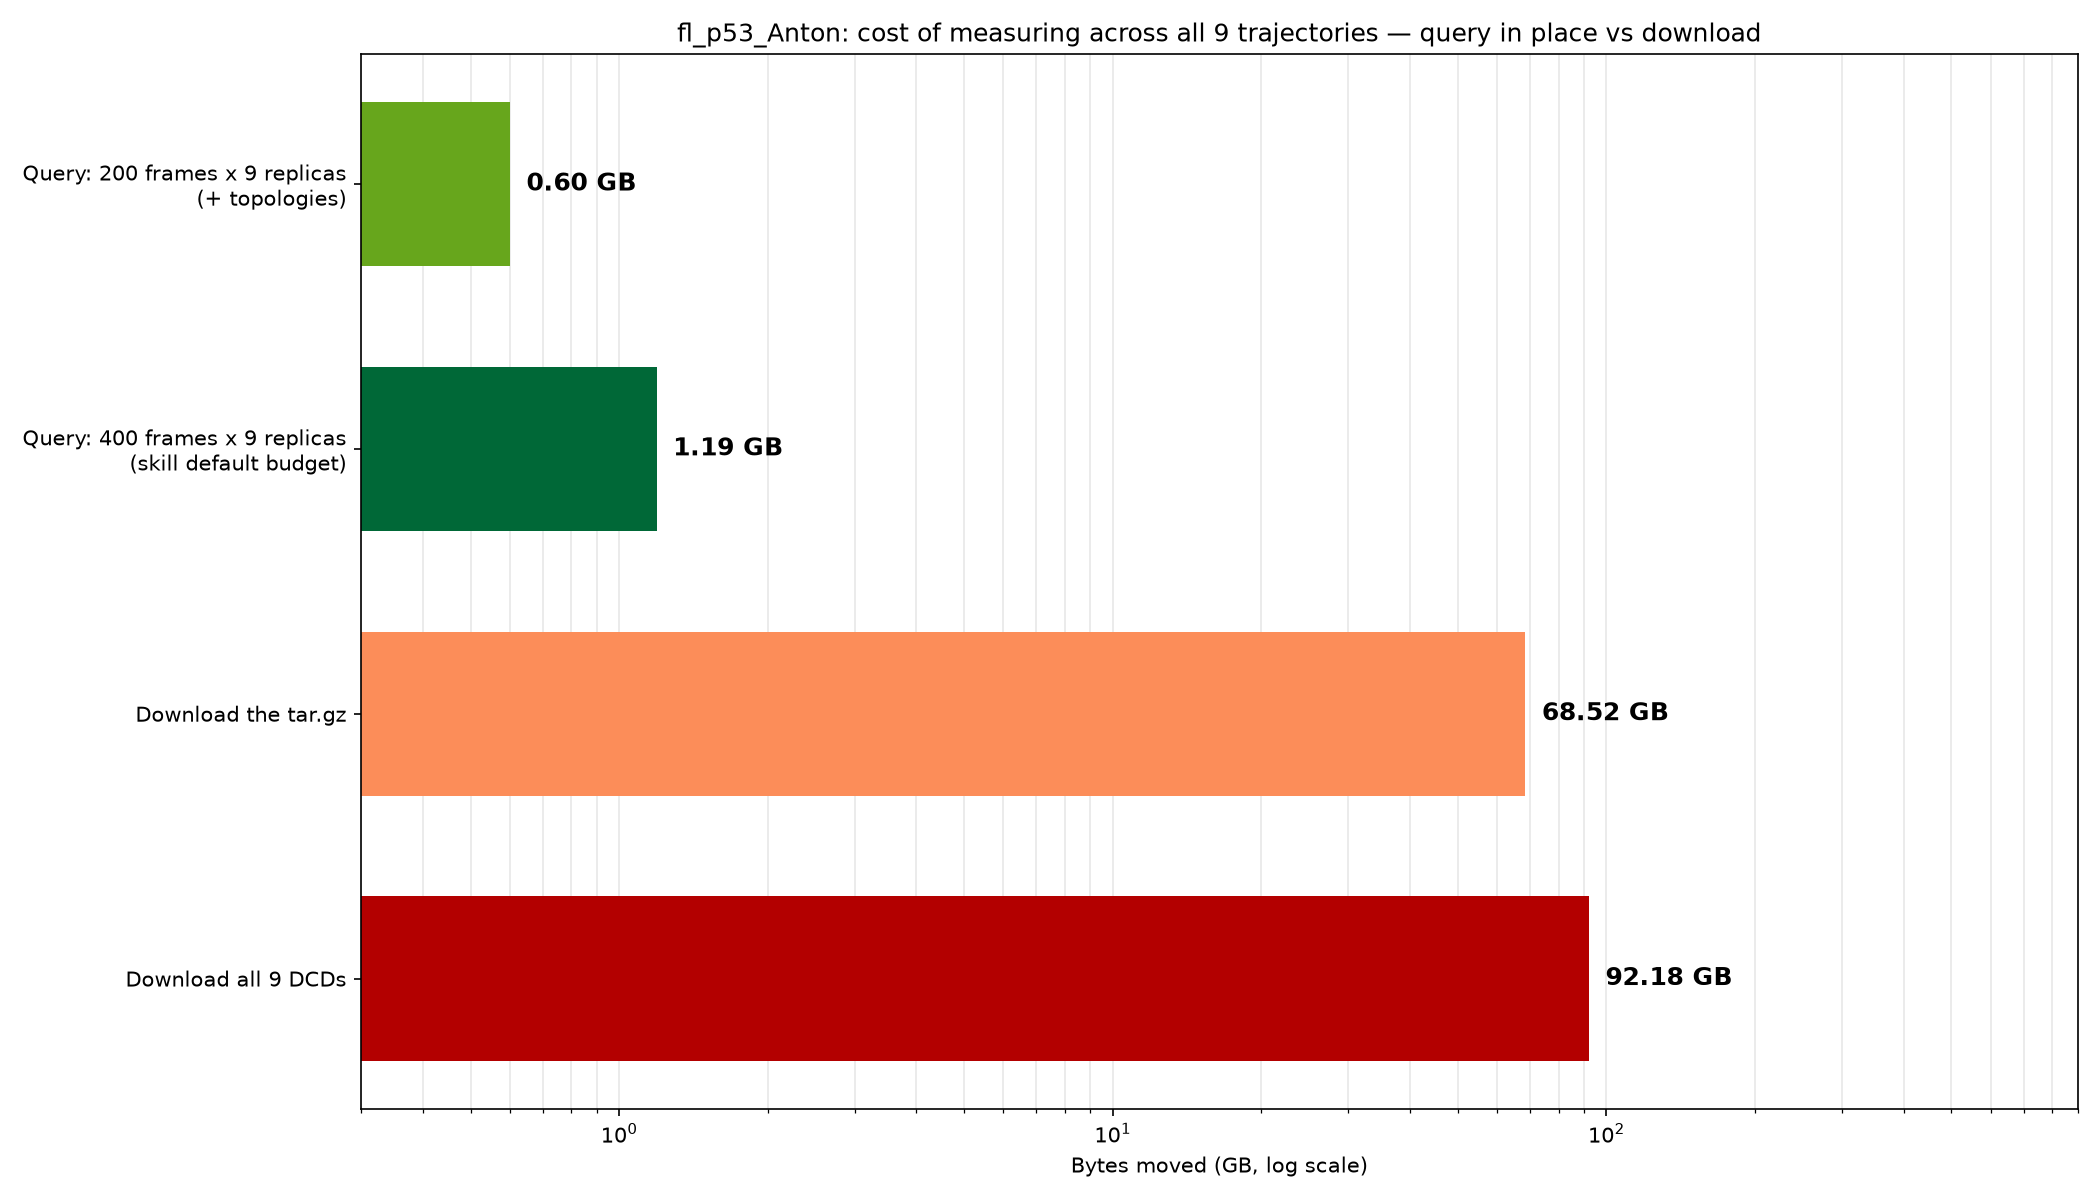

**Files written** : per-replica inventory at [p53_collection_inventory.csv](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/_p53_cancer_mutants_sage_/p53_collection_inventory.csv) and the script at [p53_inventory.py](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/_p53_cancer_mutants_sage_/p53_inventory.py). This answer was computed entirely from the skill's measured catalogue — zero bytes fetched from the server. If you'd like, I can run an actual cross-condition measurement (e.g. DBD RMSF per condition, using all three replicas) — it would cost about 1.2 GB and a few minutes.

In [1]:
%%ask
What simulations are in this p53 collection? For each condition tell me how many
replicas there are, how long each one ran, and how large the files are.

Then tell me how much data you would have to move to measure something across all
nine of them, compared with downloading the files.

## 2. Does the cancer mutation change how the DNA-binding domain moves?

G245S and Y220C both sit in the DNA-binding domain and both destabilise p53 in
patients, but by different routes. The question is whether that shows up as a
difference in flexibility.

All nine replicas processed in 4.2 minutes. The analysis is complete — here are the results.

## What I measured

Cα RMSF over the DNA-binding domain (MON1 residues 94–292, 199 residues), computed identically for all nine trajectories: 201 frames spread evenly over each replica's full 7.5 µs (~37 ns stride), read by HTTP range request straight out of the remote DCDs.

**Cost** : 593 MB of frames moved (~66 MB per replica) plus ~8 MB of topologies, out of the 92 GB the nine trajectories hold — **0.65% of the archive, 254 s of runtime** . No file was downloaded whole.

## Domain-level result: how much does the DBD move?

Domain-mean RMSF (average over all 199 DBD residues), in Å — mean of 3 replicas ± SD between replicas, with the individual replicas shown so the spread is visible:

| Condition | Replica 1 | Replica 2 | Replica 3 | Mean ± SD (between replicas) |
| --- | --- | --- | --- | --- |
| wild type | 1.492 | 1.815 | 1.427 | **1.578 ± 0.207** |
| G245S mutant | 1.511 | 1.226 | 1.254 | **1.330 ± 0.157** |
| Y220C mutant | 1.610 | 1.520 | 1.527 | **1.552 ± 0.050** |

**Verdict on your question — is any difference bigger than the run-to-run variation?**

- **Y220C vs wild type: no.** The means differ by 0.026 Å, an order of magnitude smaller than wild type's own replica spread (±0.21). These two conditions are indistinguishable at the domain level.
- **G245S vs wild type: borderline, and I would not call it.** G245S is nominally 16% less flexible (1.33 vs 1.58 Å), but that 0.25 Å gap is about the same size as wild type's replica-to-replica SD. Wild type replica 2 (1.82 Å) is the outlier driving the wild-type mean up, and it overlaps nothing in G245S — but G245S replica 1 (1.51) sits inside wild type's range (1.43–1.82). With n=3, this is a hint, not a result.
- **The one clean separation is mutant vs mutant** : every G245S replica (1.23–1.51) falls below every Y220C replica (1.52–1.61) — no overlap across all six runs. Still only three replicas per side, but it's the most reproducible pattern in the data: in this ensemble G245S is the "quietest" DBD and Y220C behaves most like wild type.

## Per-residue structure (top panel of the plot)

The flexibility profile has the same shape in all three conditions — the same residues are the mobile ones everywhere: the 117–120 stretch at the DBD N-terminal end, residue 185 in the L1 loop, and 224–227 at the start of the L2 loop (all peaking near 4–5.6 Å). The differences between conditions are of degree, not of pattern:

- **Y220C** runs hottest at the 117–120 peak (up to 5.63 Å, the largest single-residue RMSF in the dataset) and is slightly more flexible than wild type through most of the domain — but its three replicas agree remarkably tightly (±0.05), so this is its most trustworthy feature.
- **G245S** is uniformly a touch below the wild-type trace along the whole domain, including at its own mutation site flank (residues 237–250: 0.94 Å vs wild type 1.13 Å — inside the spread).
- **Locally at the mutation sites** , neither mutant shows a mobility increase relative to wild type beyond replica noise: the 213–230 region flanking Y220 reads 2.49 Å (WT), 2.08 ± 0.59 (G245S), 2.45 ± 0.35 (Y220C); the 237–250 region flanking G245S reads 1.13 ± 0.32 (WT), 0.94 ± 0.19 (G245S), 1.05 ± 0.14 (Y220C).

So the honest summary: **the DNA-binding domain moves the same way in all three conditions; G245S is modestly and consistently the least mobile, Y220C is wild-type-like on average but with the most reproducible (tightest) replica agreement.** No condition difference at any location exceeds what replica-to-replica variation produces, except the clean G245S-below-Y220C ordering.

## The plot

Top: per-residue RMSF across the DBD, solid line = 3-replica mean, shaded band = ±1 SD between replicas, with the two mutation-site positions marked. Bottom: domain-mean RMSF per condition — bars are condition means, error bars the between-replica SD, black dots the three individual replicas, so you can judge overlap directly.


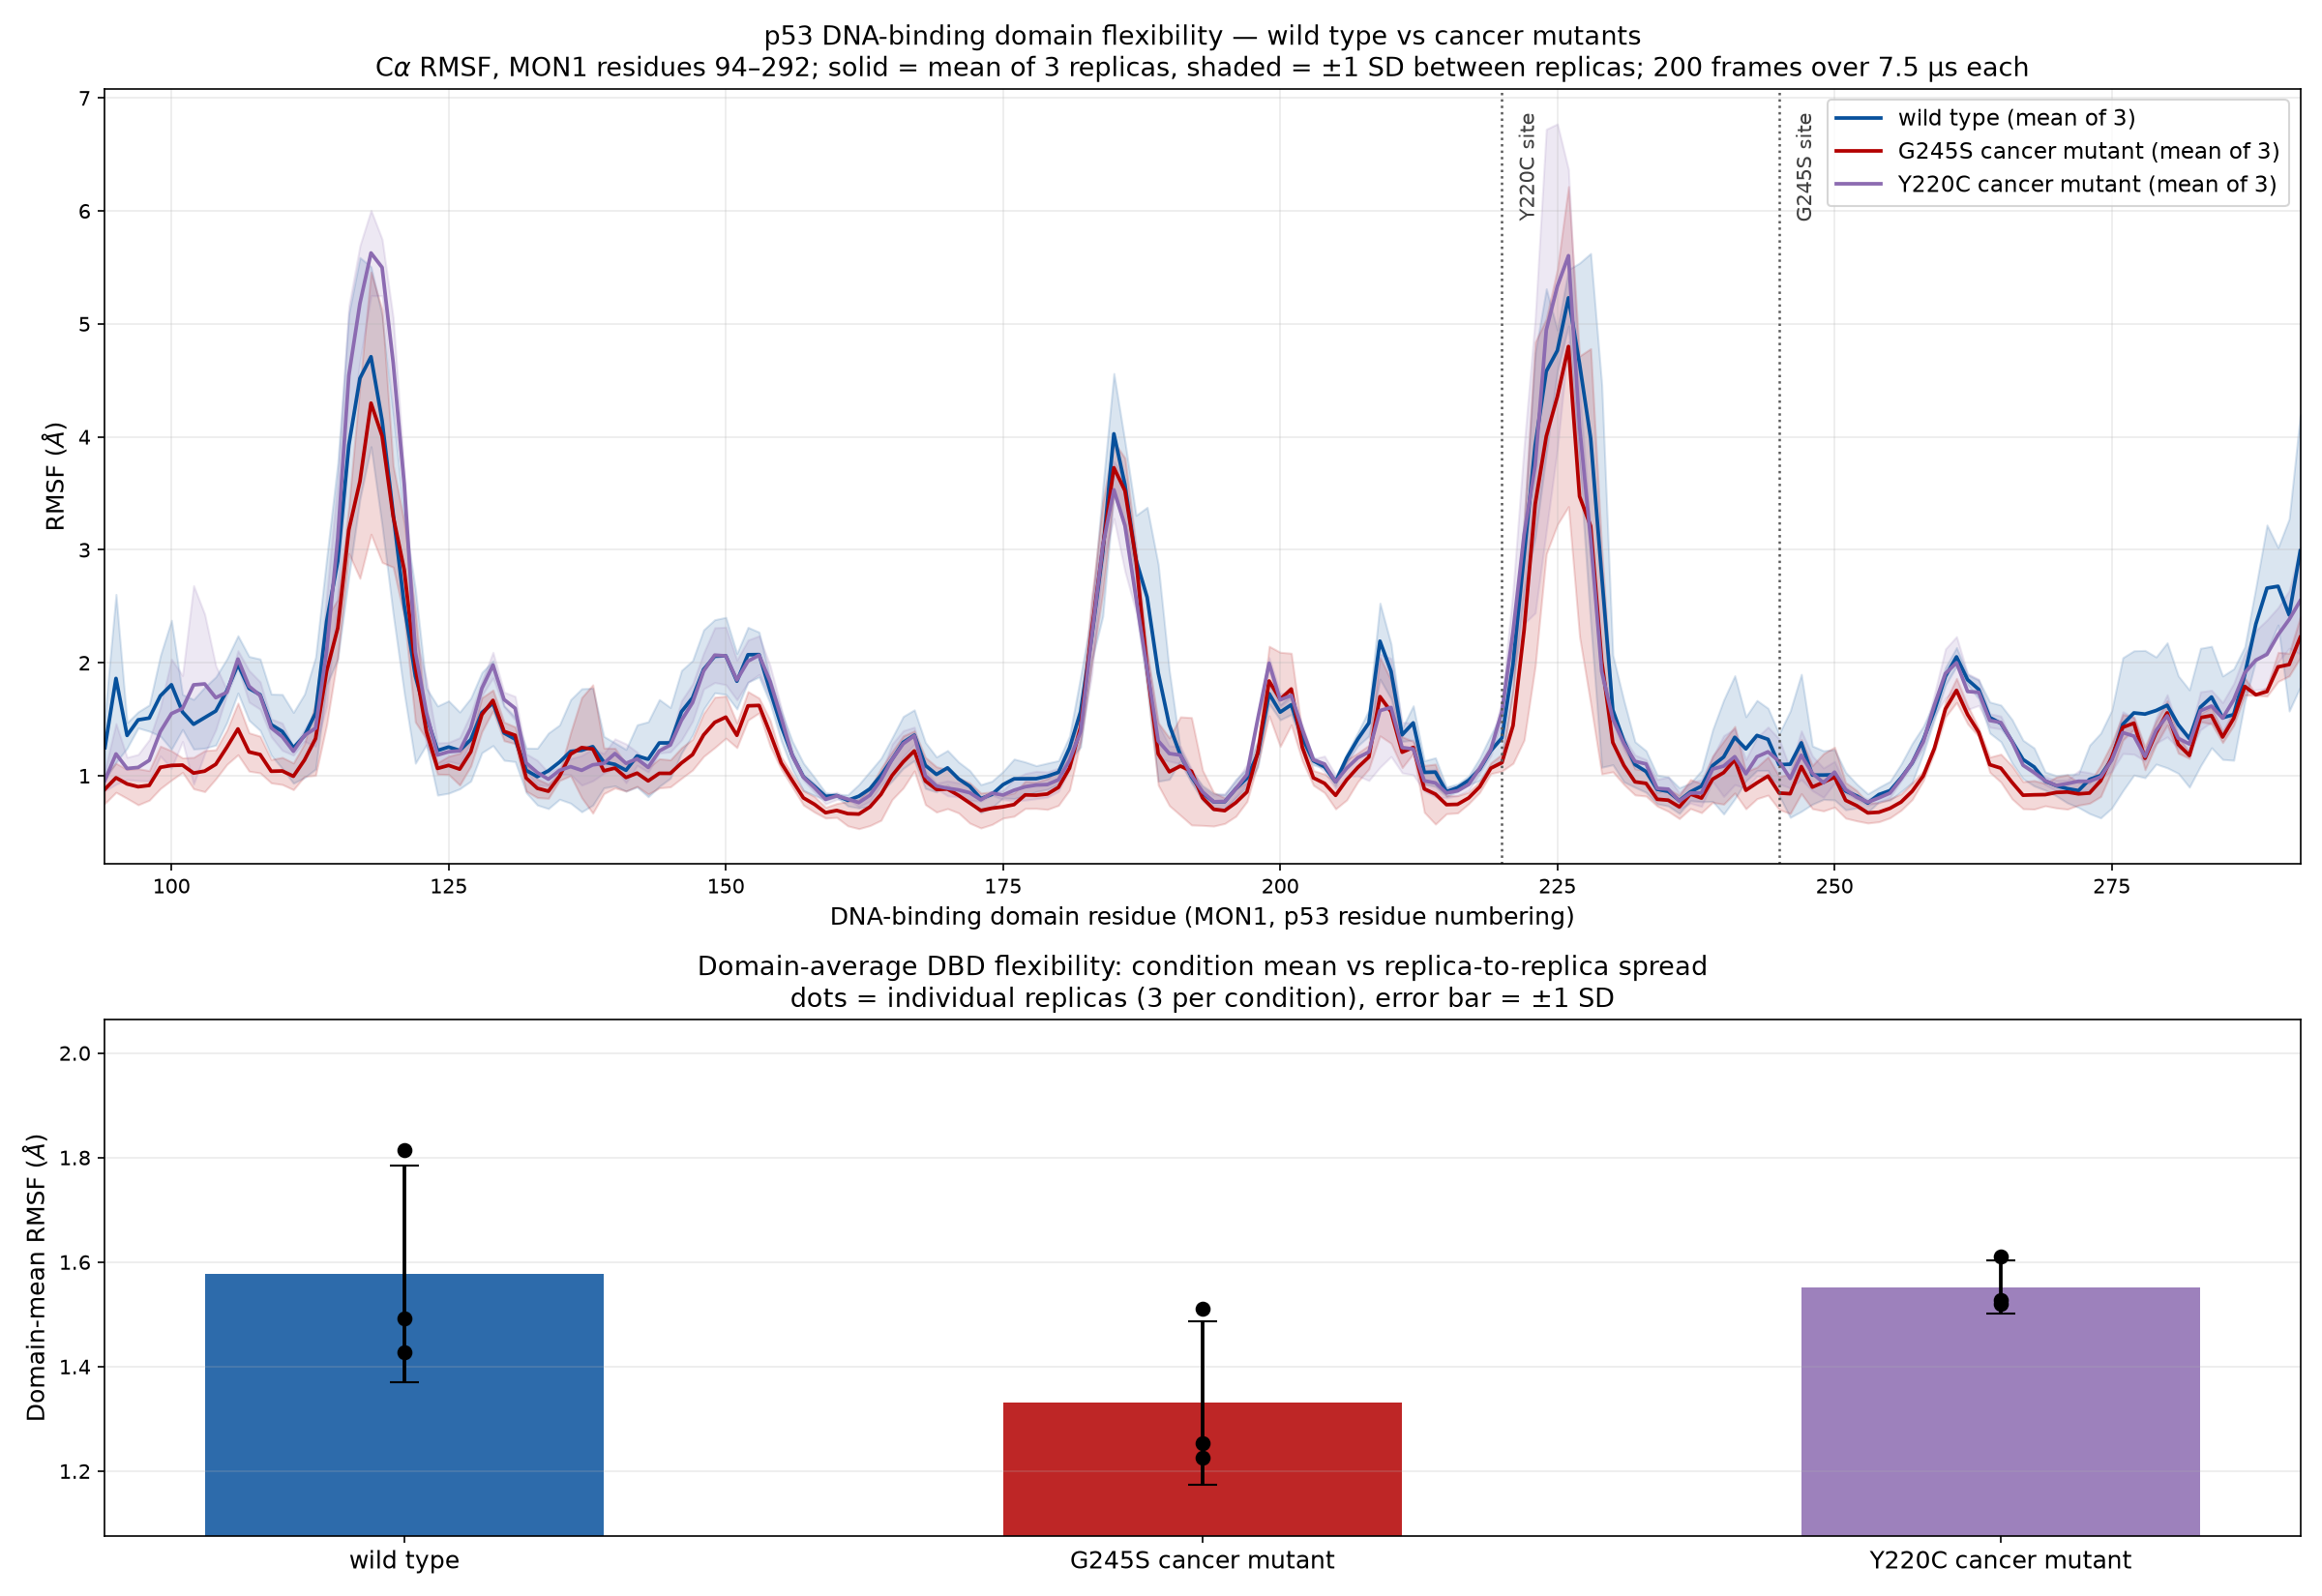

**Files written** : [p53_dbd_rmsf.png](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/_p53_cancer_mutants_sage_/p53_dbd_rmsf.png) (figure), [p53_dbd_rmsf.csv](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/_p53_cancer_mutants_sage_/p53_dbd_rmsf.csv) (1,791 rows: every residue × replica), [p53_dbd_rmsf_summary.csv](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/_p53_cancer_mutants_sage_/p53_dbd_rmsf_summary.csv) (condition-level table), [p53_dbd_rmsf.py](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/_p53_cancer_mutants_sage_/p53_dbd_rmsf.py) (script).

One methodological note: RMSF values come from 201-frame subsampling of each trajectory rather than all 31,250 frames — that captures the slow conformational fluctuations (which dominate at µs scale) and is identical treatment across conditions, so comparisons are fair; absolute RMSFs would be slightly smoothed by the 37 ns stride. If you want to firm up the G245S-vs-Y220C separation, the cheap next step is 400 frames per replica (~1.2 GB total) or a per-block RMSD analysis of just those six runs.

In [1]:
%%ask
Compare how much the DNA-binding domain moves in the wild type against each of the
two cancer mutants.

Use all three replicas for every condition and show me the spread between replicas
alongside the average, so I can see whether any difference is bigger than the
run-to-run variation. Plot it.

## 3. Is the effect at the mutation site, or somewhere else?

# Where the G245S difference sits

The **G245S mutant** differs most from wild type at the domain level:

| Comparison | Mean DBD RMSF | Difference from wild type |
|---|---:|---:|
| Wild type | 1.578 Å | — |
| G245S | 1.330 Å | −0.248 Å |
| Y220C | 1.552 Å | −0.026 Å |

The residue-level comparison below therefore uses **G245S versus wild type** , averaging the Cα RMSF independently across all three replicas of each condition. It covers residues 94–292 of one DNA-binding-domain chain.


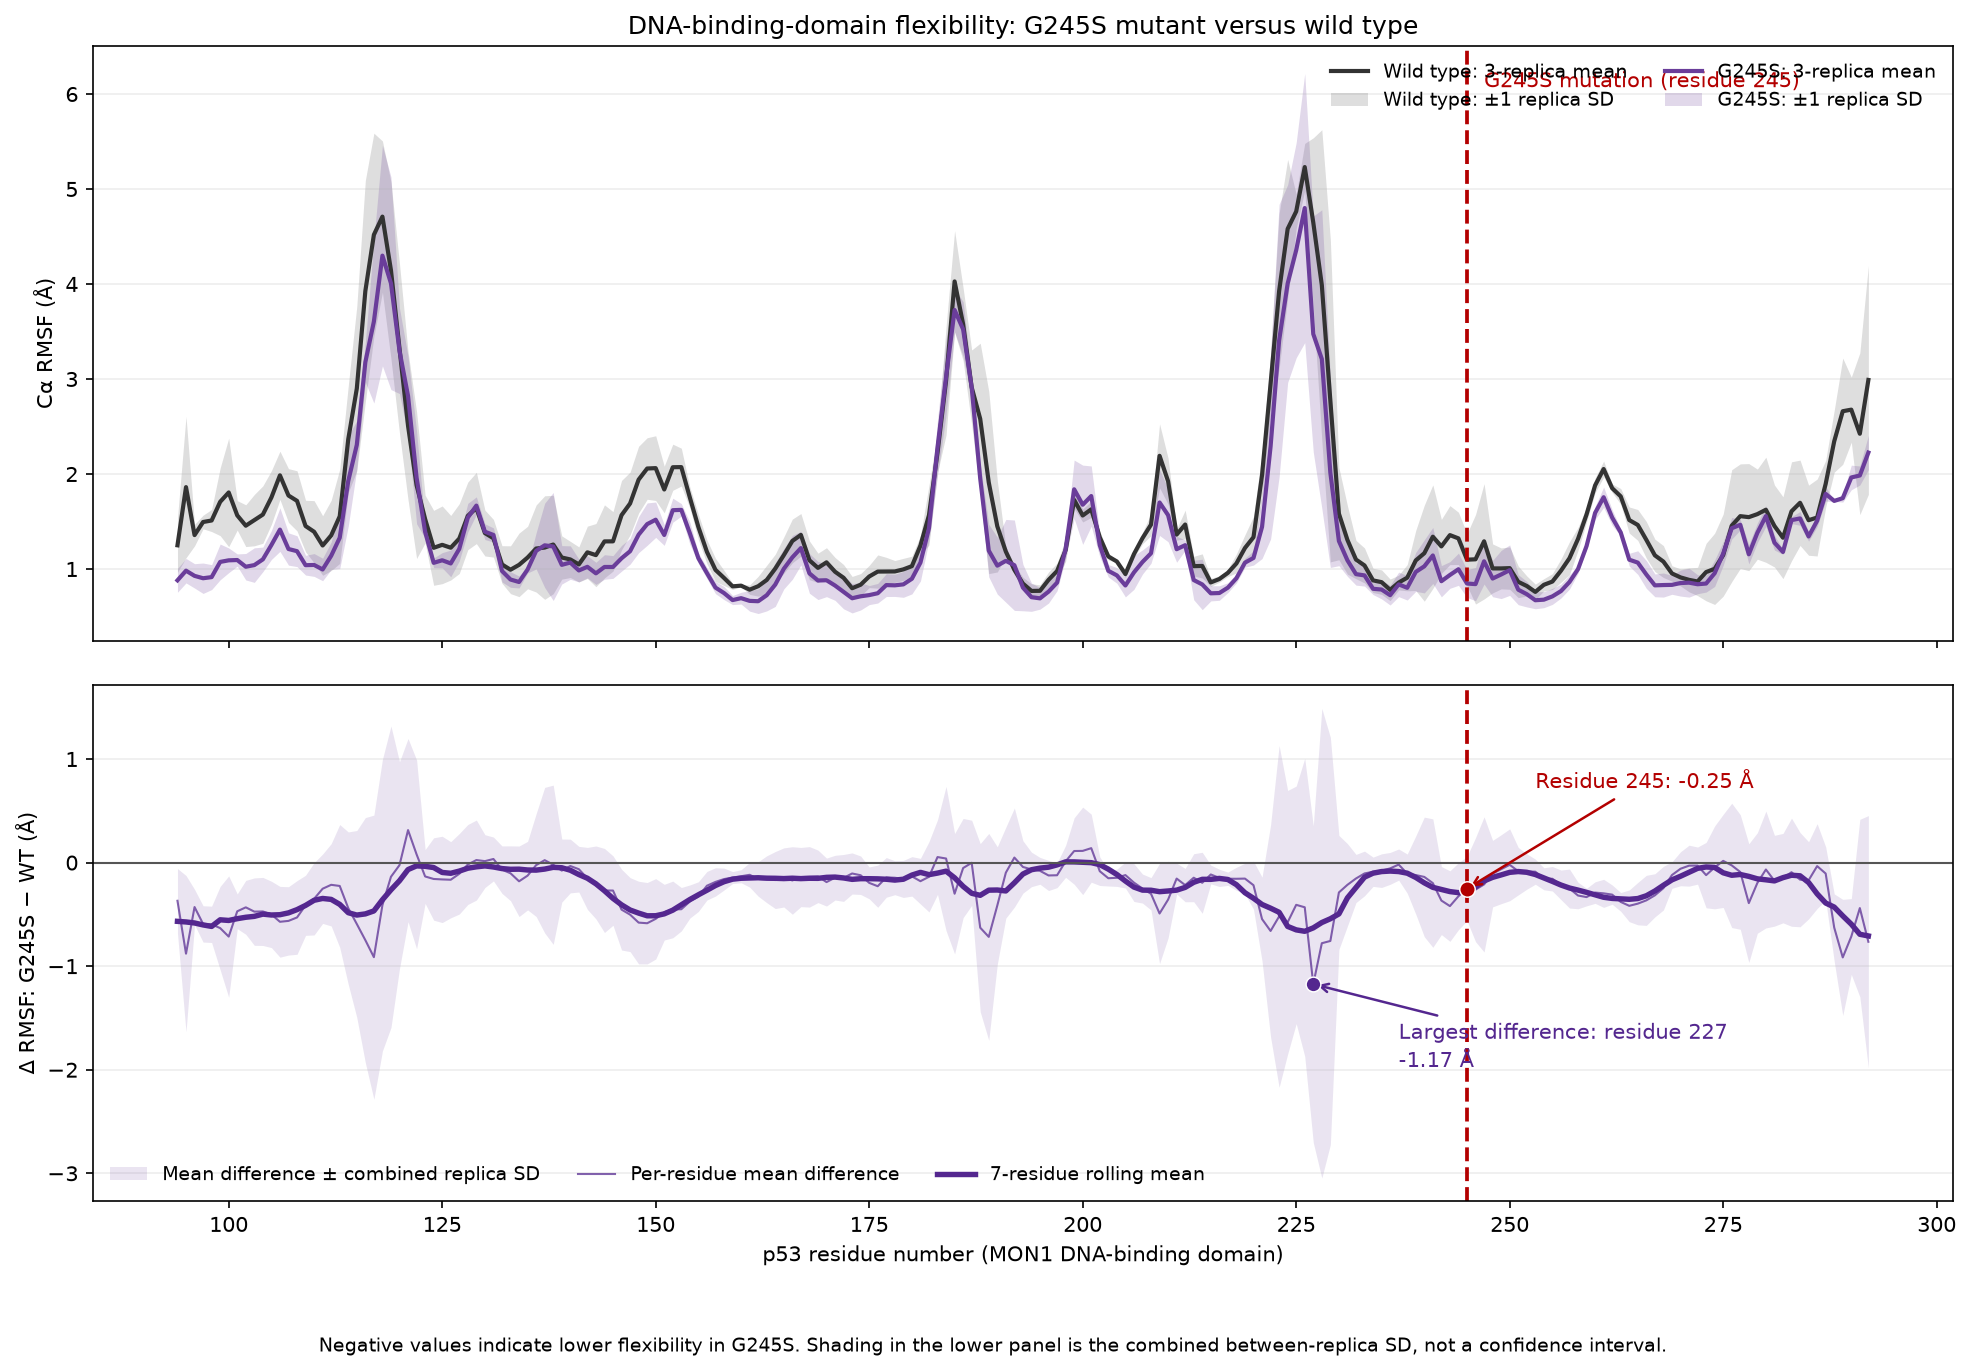

In the upper panel, each line is the three-replica mean and each band is ±1 SD between replicas. The lower panel is the direct residue-wise difference:

\[
\Delta\mathrm{RMSF}=\mathrm{RMSF}_{G245S}-\mathrm{RMSF}_{WT}
\]

Negative values mean the G245S mutant is less mobile. The mutation at residue 245 is marked by the vertical dashed line and point.

## Main result

**The reduction is not concentrated at the mutated residue.** Residue 245 participates in a modest local reduction, but larger changes appear in several regions farther along the sequence.

At the mutation site:

- **Wild-type RMSF at residue 245** : 1.098 Å.
- **G245S RMSF at residue 245** : 0.848 Å.
- **Difference** : −0.251 Å, or approximately 23% lower in G245S.
- **Rank by absolute difference** : 74th largest of the 199 DBD residues—not a dominant peak.
- **Combined between-replica SD** : 0.310 Å, slightly larger than the 0.251 Å difference.

The mutation-centered region, residues 235–255, contains **10.6% of the DBD residues but only 6.4% of the total absolute residue-wise difference** . Its average reduction is −0.158 Å, compared with −0.258 Å outside that region. Thus, the effect is actually weaker near residue 245 than across the remainder of the domain.

## Where the larger differences occur

| Region or residue | Sequence distance from residue 245 | G245S − WT | Interpretation |
|---|---:|---:|---|
| Residues 94–110 | 135–151 residues away | Mostly −0.35 to −0.71 Å | Broad reduction at the N-terminal edge of the DBD |
| Residues 114–117 | 128–131 residues away | Down to −0.91 Å | Reduction around a highly mobile DBD segment |
| Residues 221–229 | 16–24 residues away | Down to −1.17 Å | Largest individual difference, but also substantial replica variation |
| **Residue 245** | **Mutation site** | **−0.25 Å** | Modest local reduction |
| Residues 258–265 | 13–20 residues away | Approximately −0.29 to −0.42 Å | Broader reduction downstream of the mutation |
| Residues 288–292 | 43–47 residues away | Down to −0.92 Å | Distal C-terminal DBD reduction |

The largest single-residue difference is at **residue 227** , 18 residues before the mutation:

- Wild type: 4.647 Å.
- G245S: 3.474 Å.
- Difference: **−1.174 Å** .
- Combined replica SD: 1.529 Å.

That is nearly five times the difference at residue 245, although its large replica spread means it should not be treated as a precisely localized, independently significant effect.

A potentially more reproducible distal signal occurs near the DBD’s C-terminal end. At residue 289:

- Wild type: 2.661 Å.
- G245S: 1.746 Å.
- Difference: **−0.915 Å** .
- Combined replica SD: 0.561 Å.

The N-terminal edge, residues 94–110, also shows a broad rather than isolated reduction. Because adjacent residues move together in the same direction, this is more suggestive of a region-level conformational effect than a single noisy residue.

## Interpretation

The G245S result looks like a **distributed change in domain dynamics** , not a sharp mobility anomaly centered on residue 245:

1. Residue 245 itself is moderately less mobile, but its difference is within the combined replica spread.
2. The mutation-centered ±10-residue window contributes less difference than expected from its size.
3. Larger reductions occur around residues 221–229, at the N-terminal DBD edge, and near residues 288–292.
4. Much of the profile is negative, consistent with the lower overall G245S domain RMSF rather than a narrowly localized disturbance.
5. Some of the largest peaks—especially residue 227—also have substantial run-to-run variability. With only three replicas, individual-residue peaks should therefore be interpreted as locations of interest rather than definitive residue-specific effects.

**Conclusion** : G245S does not mainly change the motion of residue 245 itself. Its strongest apparent effect is a broader reduction in DNA-binding-domain flexibility, with the largest residue-wise changes occurring **16–18 residues upstream around 227 and much farther away at both ends of the analyzed domain** .

This calculation reused the prior nine-replica RMSF table, so it moved **no additional trajectory data** . The numerical residue profile is available in [p53_g245s_vs_wt_per_residue.csv](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/_p53_cancer_mutants_sage_/p53_g245s_vs_wt_per_residue.csv), including both condition means, their between-replica SDs, and the direct difference at every residue.

In [1]:
%%ask
For whichever mutant differs most from the wild type, show me where along the chain
the difference actually sits — per residue, averaged over the replicas.

Is the change concentrated at the mutated residue itself, or does it show up
somewhere further away? Mark the mutation site on the plot.

## 4. Does it reach the DNA?

p53 is a transcription factor; what matters clinically is whether it still grips its
response element. The simulations include the p21 DNA duplex.

# Protein–DNA contact comparison

## Plain answer

- **G245S** : **Yes—a moderate reduction in protein–DNA contact is larger than the usual replica-to-replica spread.** The signal appears in both the number of contacting protein residues and the number of heavy-atom contacts. However, with only three replicas, it is suggestive rather than definitive.
- **Y220C** : **No—the apparent increase is not meaningful relative to its replica spread.** One Y220C replica has fewer contacts than wild type, while the other two have more; its run-to-run variation is larger than the condition difference.

## Primary measure: how many p53 residues contact DNA?

I counted a p53 residue as contacting DNA when any of its heavy atoms came within **4.5 Å** of any DNA heavy atom. The count covers the **entire p53 tetramer** , not just one monomer.

For each replica, the table reports its average over 201 snapshots spanning the full 7.5 µs trajectory. The final column is the condition mean ± sample SD among the three independent replica means.

| Condition | Replica 1 | Replica 2 | Replica 3 | Three-replica mean ± SD | Difference from WT |
|---|---:|---:|---:|---:|---:|
| Wild type | 103.4 | 108.6 | 103.2 | **105.0 ± 3.0 residues** | — |
| G245S | 93.4 | 96.6 | 103.4 | **97.8 ± 5.1 residues** | **−7.2 residues, −6.9%** |
| Y220C | 99.7 | 118.7 | 119.8 | **112.7 ± 11.3 residues** | **+7.7 residues, +7.3%** |

### G245S versus wild type

The G245S reduction is **7.2 contacting residues** , compared with replica SDs of 3.0 residues for wild type and 5.1 for G245S. The difference is approximately **1.7 times the pooled between-replica SD** .

The replica ranges almost separate:

- **Wild type** : 103.2–108.6 contacting residues.
- **G245S** : 93.4–103.4 contacting residues.

Two G245S replicas are clearly below every wild-type replica. The third G245S replica is essentially tied with the low end of wild type.

**Interpretation** : the G245S reduction is larger than typical run-to-run variation and is therefore a **meaningful-looking moderate effect** , but it is not an all-replicas-clean separation. With only three independent runs per condition, I would not describe it as conclusive.

### Y220C versus wild type

The Y220C mean is 7.7 residues above wild type, but its between-replica SD is **11.3 residues** , larger than the difference itself. The difference is only **0.93 times the pooled between-replica SD** .

The individual replicas tell the important story:

- Y220C replica 1: 99.7 residues, below all three wild-type replicas.
- Y220C replicas 2 and 3: 118.7 and 119.8 residues, above wild type.

**Interpretation** : the apparent Y220C increase is **not meaningful given the replica spread** . Its condition mean is being formed from substantially different replica behaviors.

## Cross-check: heavy-atom contact pairs

As a second measure, I counted every protein–DNA heavy-atom pair within the same 4.5 Å cutoff.

| Condition | Replica 1 | Replica 2 | Replica 3 | Three-replica mean ± SD | Difference from WT |
|---|---:|---:|---:|---:|---:|
| Wild type | 1,305 | 1,465 | 1,293 | **1,355 ± 96 pairs** | — |
| G245S | 1,169 | 1,175 | 1,313 | **1,219 ± 81 pairs** | **−136 pairs, −10.0%** |
| Y220C | 1,224 | 1,504 | 1,649 | **1,459 ± 216 pairs** | **+104 pairs, +7.7%** |

This second metric supports the same conclusion:

- The G245S difference is about **1.5 pooled replica SDs** below wild type: a moderate reduction that exceeds ordinary run-to-run spread, although not decisively.
- The Y220C difference is only **0.62 pooled replica SDs** above wild type: much smaller than its run-to-run variation.

The residue-count metric is the better primary result because mutations alter side-chain composition—the three conditions do not contain exactly the same number of heavy atoms. Counting distinct contacting residues is less sensitive to that compositional difference. The atom-pair result is useful because it independently points in the same direction.

## Plot

Bars show the condition average, error bars show ±1 SD between the three replica means, and the black dots are the individual replicas.


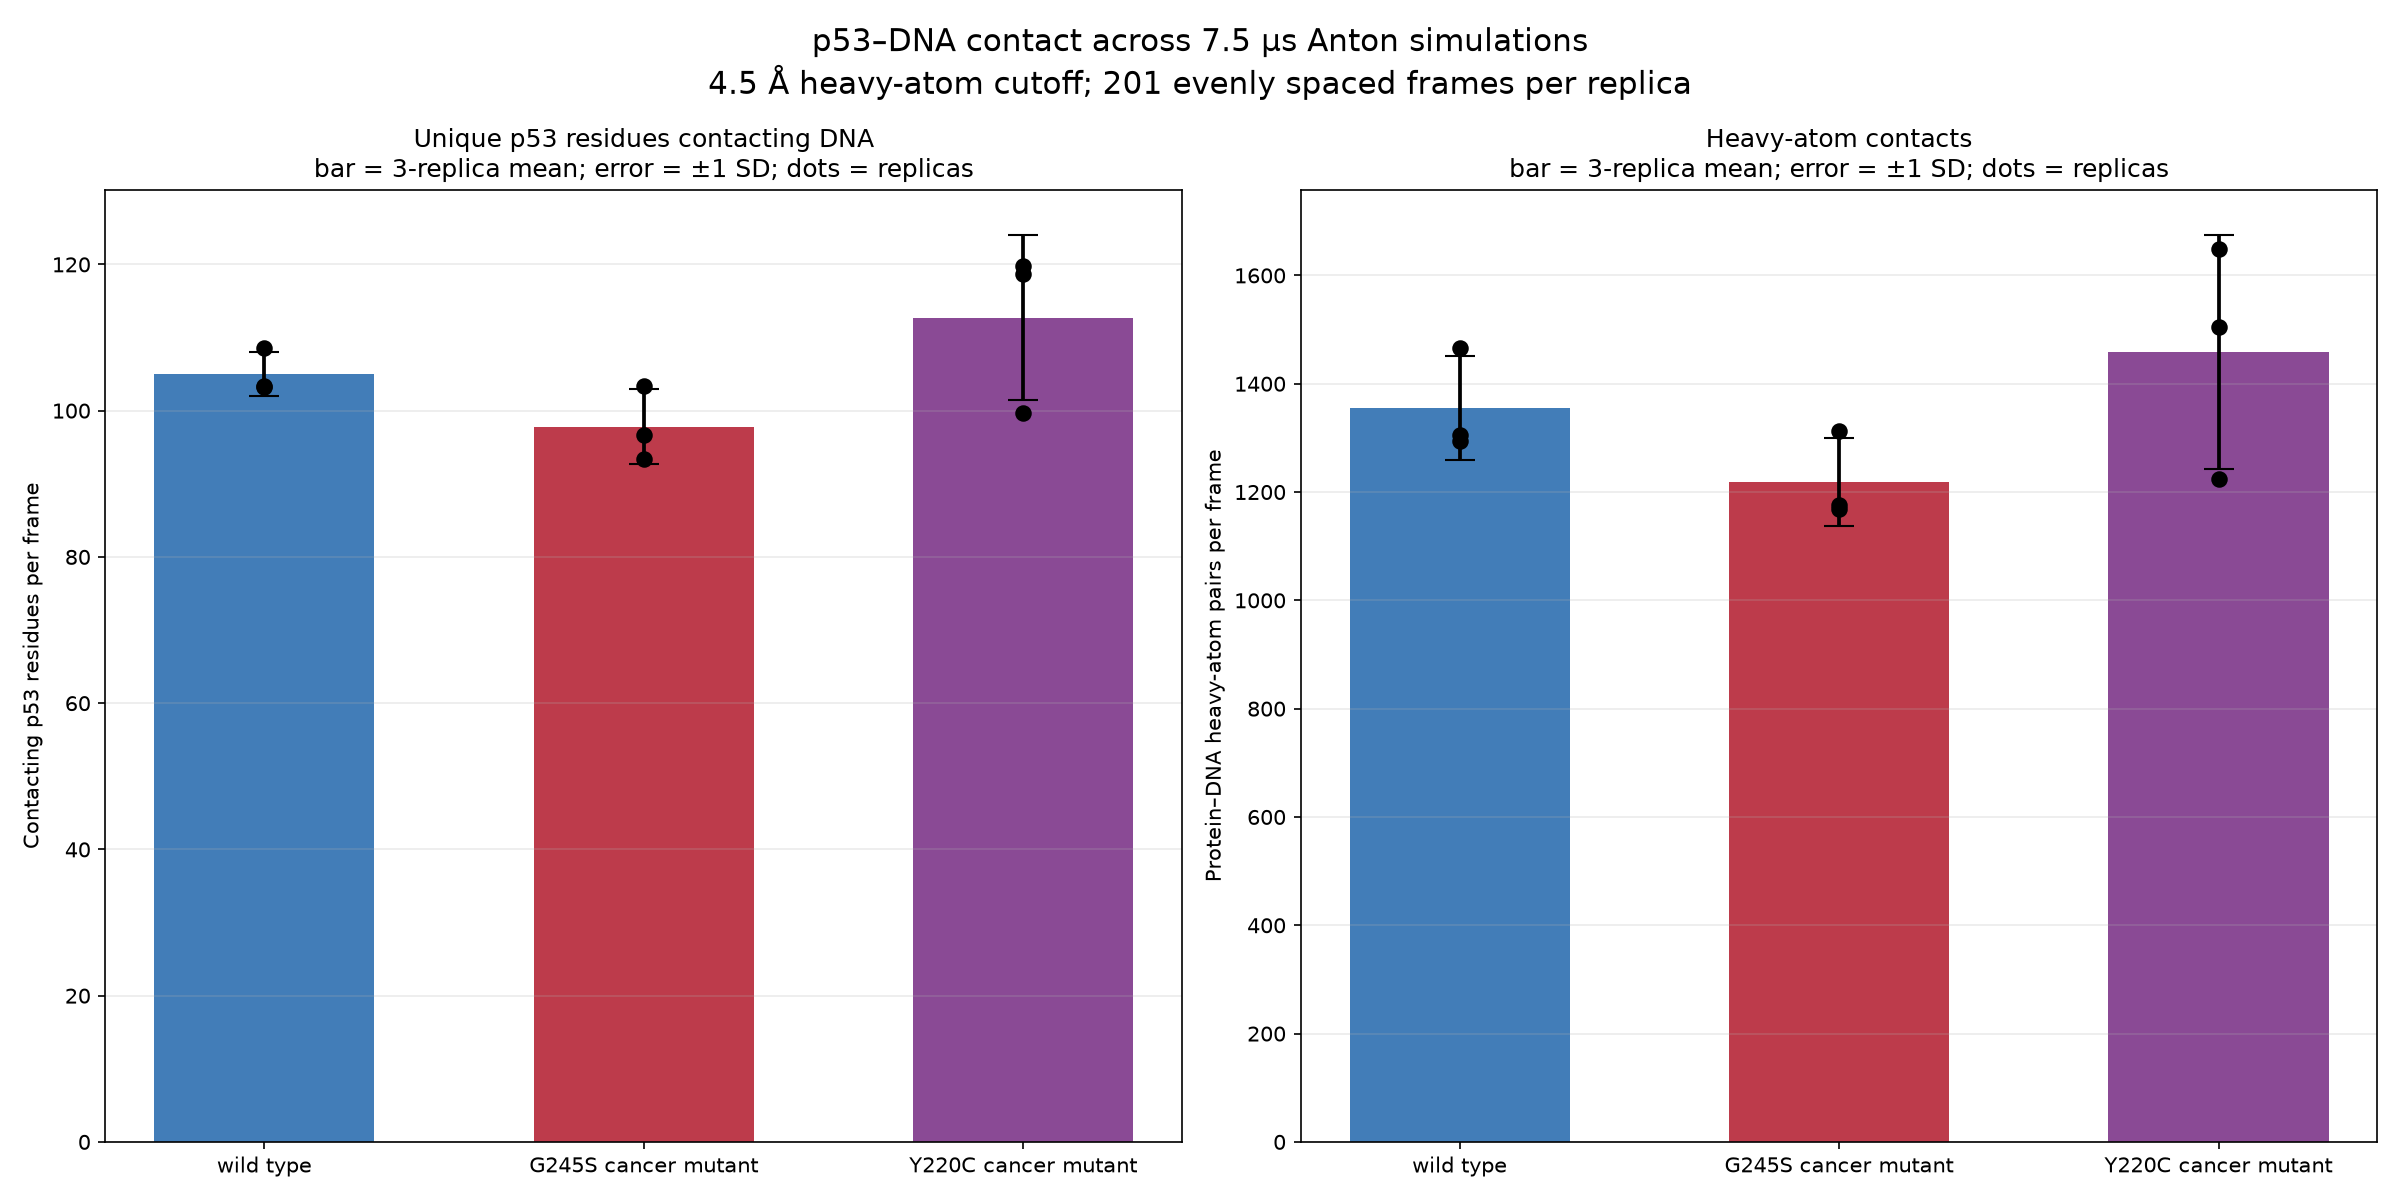

## Bottom line

| Mutant versus WT | Contact change | Larger than replica variation? | Plain conclusion |
|---|---:|---|---|
| G245S | Approximately 7% fewer contacting residues and 10% fewer atom-pair contacts | **Yes, moderately** | Likely reduced protein–DNA contact, but three replicas are insufficient for a definitive claim |
| Y220C | Approximately 7% more contacting residues and 8% more atom-pair contacts | **No** | No reliable difference from wild type; the apparent increase is dominated by replica variation |

The strongest defensible conclusion is therefore: **G245S shows a moderate reduction in the extent of the p53–DNA interface, whereas Y220C cannot be distinguished from wild type because its replicas vary too much.**

## Sampling and data cost

- **Replicas analyzed** : all nine—three per condition.
- **Snapshots** : 201 per replica, 1,809 total.
- **Time represented** : 0–7.488 µs of each 7.5 µs trajectory.
- **Trajectory data moved** : 592.9 MB, plus approximately 8 MB of topology data.
- **Fraction of the nine DCD files read** : approximately 0.65% of the 92 GB collection.
- **Runtime** : 308 seconds.

The complete numerical results are available as a [condition summary CSV](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/_p53_cancer_mutants_sage_/p53_protein_dna_contacts_summary.csv), a [replica-level CSV](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/_p53_cancer_mutants_sage_/p53_protein_dna_contacts_replicas.csv), and a [frame-level CSV](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/_p53_cancer_mutants_sage_/p53_protein_dna_contacts_framewise.csv).

In [2]:
%%ask
Does the contact between the protein and the DNA differ between the wild type and
the mutants? Report it per condition with the replica spread, and say plainly
whether the difference is large enough to be meaningful given that spread.

## 5. Check against what the authors themselves published

# Comparison with the lab’s PCA extremes and final structures

## Bottom line

The published structures provide a **mixed validation** of the trajectory measurements:

- **Agreement on where the DBD is mobile** : strong for wild type and moderate for both mutants. The lab’s principal-component extremes emphasize many of the same residue ranges identified by the replica-averaged RMSF analysis.
- **Agreement for Y220C at the whole-domain level** : both analyses portray Y220C as broadly similar to wild type.
- **Agreement that G245S is not a local disturbance at residue 245** : the mutation site is one of the least-displaced residues in the lab’s leading PCs. The important motion is distributed elsewhere.
- **Disagreement on G245S’s overall amount of motion** : our trajectory RMSF made G245S about 16% less mobile than wild type, but the lab’s PCA extremes have a slightly *larger* total span. The PCA structures therefore do **not** confirm that G245S is globally quieter.
- **Final structures do not define distinct mutant end states** : mutant-to-WT DBD distances overlap the variation among final frames from the same condition.
- **Final-frame DNA contacts preserve the earlier ordering** , with G245S below WT and Y220C above WT, but neither endpoint difference exceeds the final-frame replica spread. The endpoints alone would not support a meaningful contact difference.

## Data fetched

I fetched:

- **12 canonical PCA extremes** : PC1 minimum, PC1 maximum, PC2 minimum, and PC2 maximum for each of WT, G245S, and Y220C.
- **Nine final-frame structures** : one 7.5 µs endpoint from every replica.
- **Total transferred** : 46.051 MB.
- **Additional trajectory data transferred** : none.

The catalogue also lists FTMap derivatives, a WT PCA origin, and a WT chain-B duplicate. Those are auxiliary products rather than additional condition × PC min/max extremes, so they were not counted as independent structures. The fetched-product inventory, including every source URL and local path, is in [p53_published_structures_inventory.csv](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/_p53_cancer_mutants_sage_/p53_published_structures_inventory.csv).

## 1. Overall DBD motion: partial agreement

The lab’s PCA span is the Cα RMSD between its minimum and maximum structure along a principal component, using all four DBDs. For comparison, the trajectory result is the domain-mean Cα RMSF calculated previously from 201 snapshots in each of three replicas.

These are related but **not numerically equivalent** :

- RMSF measures average temporal dispersion around a trajectory mean.
- A PCA min–max span measures the observed extreme excursion along one selected collective mode.
- The PCA products do not provide a replica SD.

| Condition | Trajectory DBD RMSF, mean ± replica SD | Lab PC1 min–max span | Lab PC2 min–max span | Combined two-PC span |
|---|---:|---:|---:|---:|
| Wild type | 1.578 ± 0.207 Å | 4.378 Å | 5.224 Å | 4.820 Å |
| G245S | 1.330 ± 0.157 Å | 5.200 Å | 4.737 Å | 4.974 Å |
| Y220C | 1.552 ± 0.050 Å | 5.117 Å | 4.904 Å | 5.012 Å |

The fitted min–max RMSDs were nearly identical to the raw spans, so these results are not caused by a residual rigid translation or rotation.

### Where this agrees

**Y220C and WT have similar overall motion in both analyses.**

- Trajectory RMSF: Y220C is only 0.026 Å below WT, much less than WT’s replica spread.
- PCA span: Y220C is about 4% above WT.
- Those signs differ, but both differences are small enough that the appropriate interpretation is the same: **Y220C is broadly WT-like at the whole-domain level** .

### Where this does not agree

**The PCA extremes do not reproduce the lower average motion observed for G245S.**

- Trajectory RMSF: G245S was 0.248 Å, or approximately 16%, below WT.
- PCA composite span: G245S is 0.154 Å, or approximately 3%, above WT.
- Therefore, the lab’s two leading extreme motions show G245S sampling excursions at least as large as WT, not a uniformly compressed DBD ensemble.

This is not necessarily a computational contradiction: a trajectory can have lower average fluctuation while still occasionally reaching broad extremes along one or two modes. But it means the PCA structures **do not independently validate the claim that G245S is globally less mobile** . That claim remains a result of the replica-averaged RMSF calculation and was already only borderline relative to WT’s run-to-run spread.

## 2. Where along the chain the motion occurs: substantial agreement

For every residue, I calculated its displacement between each lab PCA minimum and maximum, averaged over all four monomers, and combined PC1 and PC2. I then compared that profile with the three-replica RMSF profile.

| Condition | Pearson correlation: PCA profile vs RMSF profile | Spearman correlation | Shared residues among the 20 largest peaks |
|---|---:|---:|---:|
| Wild type | **0.805** | 0.767 | 15 of 20 |
| G245S | **0.612** | 0.519 | 11 of 20 |
| Y220C | **0.606** | 0.609 | 9 of 20 |

These are positive and highly non-random correlations. The strongest agreement is in wild type; the mutant profiles are still moderately concordant.

Both methods identify motion around several of the same ranges:

- **Residues 116–121** .
- **Residues 185–188** , particularly prominent in G245S’s PCA structures.
- **Residues 223–228** .
- Additional terminal or downstream motion around **258–265** and **288–292** , with the relative prominence varying by condition.

Examples from the PCA extremes include:

- WT: residues 225–228, 116–120, and 290–292.
- G245S: residues 185–188, 223–228, and residue 120.
- Y220C: residues 118–121, 224–227, and 260–263.

Thus, **the lab PCA supports the locations of the flexible regions much better than it supports the condition-level ranking of total flexibility** .

## 3. Is the motion localized at either mutation?

### G245S: clear agreement that residue 245 is not the center of the motion

At residue 245:

| Measure | WT | G245S |
|---|---:|---:|
| Trajectory RMSF | 1.098 Å | 0.848 Å |
| Lab two-PC composite span | 2.206 Å | 2.566 Å |

The direction differs—RMSF is lower in the mutant while the PCA extreme span is slightly higher—but both analyses agree on the more important structural conclusion:

- Residue 245 ranks **189th of 199 DBD residues** by G245S PCA displacement.
- It is therefore in approximately the **bottom 5.5%** , not a PCA-motion hotspot.
- The largest G245S PCA changes occur around residues 185–188 and 223–228, far from or upstream of the mutation.

**Conclusion for G245S** : the lab structures strongly support the earlier conclusion that the dynamical effect is distributed through the DBD rather than concentrated at the substituted residue. They do **not** agree on whether residue 245 itself moves slightly less or slightly more.

### Y220C: weak, non-decisive local agreement

At residue 220:

| Measure | WT | Y220C |
|---|---:|---:|
| Trajectory RMSF | 1.335 Å | 1.568 Å |
| Lab two-PC composite span | 5.001 Å | 5.709 Å |

Both measures point toward somewhat greater displacement at residue 220 in Y220C. In the PCA profile, residue 220 ranks 56th of 199—above average but not among the strongest peaks.

However, the trajectory increase at residue 220 was about the same size as the combined between-replica spread. The PCA products contain no replica uncertainty with which to test that increase.

**Conclusion for Y220C** : the direction agrees locally, but the evidence is not strong enough to call residue 220 a reproducibly hypermobile site.

## 4. Do the mutants move along the same collective directions as WT?

I compared the two-dimensional space defined by PC1 and PC2 for each mutant with the WT two-PC space. A score of 1 would mean the two leading-motion subspaces are the same; 0 would mean no overlap.

| Mutant | Two-PC subspace similarity to WT | Principal angles |
|---|---:|---:|
| G245S | 0.592 | 44.9°, 63.5° |
| Y220C | 0.596 | 44.1°, 63.8° |

This is **moderate, not strong, overlap** .

It explains the mixed result:

- The same general residue regions tend to be mobile.
- The exact coordinated motions of those regions are substantially different between conditions.
- Neither mutant simply reproduces the WT PC1/PC2 motion with a different amplitude.

The detailed axis and subspace calculations are in [p53_pca_subspace_similarity.csv](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/_p53_cancer_mutants_sage_/p53_pca_subspace_similarity.csv), while the residue-level PCA/RMSF comparison is in [p53_pca_vs_rmsf_per_residue.csv](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/_p53_cancer_mutants_sage_/p53_pca_vs_rmsf_per_residue.csv).

## 5. What the nine final frames say about protein–DNA contact

I applied the same contact definition as before: a p53 residue is contacting DNA when any of its heavy atoms is within 4.5 Å of a DNA heavy atom.

| Condition | Final-frame replicas | Final-frame mean ± replica SD | Full-trajectory mean ± replica SD |
|---|---:|---:|---:|
| Wild type | 123, 144, 119 | **128.7 ± 13.4 residues** | 105.0 ± 3.0 |
| G245S | 119, 113, 124 | **118.7 ± 5.5 residues** | 97.8 ± 5.1 |
| Y220C | 131, 146, 133 | **136.7 ± 8.1 residues** | 112.7 ± 11.3 |

### Where the final structures agree

They preserve the same condition ordering:

1. Y220C has the most contact.
2. WT is intermediate.
3. G245S has the least contact.

Thus, the endpoints qualitatively support the direction of both earlier comparisons.

### Where they do not provide strong confirmation

Relative to WT:

- **G245S endpoint difference** : −10.0 contacting residues.
- **Pooled final-frame replica SD** : 10.3 residues.
- **Difference/spread** : 0.97 SD.

For Y220C:

- **Y220C endpoint difference** : +8.0 contacting residues.
- **Pooled final-frame replica SD** : 11.1 residues.
- **Difference/spread** : 0.72 SD.

Neither endpoint difference is larger than the endpoint replica spread.

Therefore:

- The published endpoints **do not independently establish a meaningful G245S contact reduction** , even though their direction is consistent with the trajectory-wide result. The trajectory-wide G245S effect was stronger at approximately 1.7 pooled replica SDs because it used the full 7.5 µs sampling rather than one snapshot.
- The endpoints agree with the earlier conclusion that **Y220C cannot be distinguished reliably from WT** .

All three conditions also have approximately 21–24 more contacting residues in their final frames than in their trajectory-wide averages. The final snapshots happen to represent relatively contact-rich conformations and should not be treated as representative averages.

The exact endpoint measurements are in [p53_final_frame_contacts.csv](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/_p53_cancer_mutants_sage_/p53_final_frame_contacts.csv).

## 6. Do the final DBD structures form separate mutant states?

After optimally aligning all 796 DBD Cα atoms, I compared the nine final structures.

| Comparison | Mean fitted DBD RMSD | Range |
|---|---:|---:|
| Among WT final frames | 3.611 Å | 3.322–4.106 Å |
| Among G245S final frames | 3.260 Å | 2.728–3.696 Å |
| Among Y220C final frames | 3.703 Å | 3.234–4.437 Å |
| WT final frames versus G245S final frames | 3.297 ± 0.505 Å | 2.663–4.304 Å |
| WT final frames versus Y220C final frames | 3.377 ± 0.387 Å | 2.849–3.825 Å |

The between-condition distances sit entirely within the scale and range of same-condition endpoint variation.

**Plain conclusion** : neither mutant finishes in a clearly separate DBD conformation. This agrees with the earlier warning that the condition differences are generally not larger than run-to-run variation.

## Synthesis plot

The figure combines:

1. Domain-level RMSF and PCA spans.
2. Per-residue RMSF versus PCA displacement.
3. The PCA displacement profile along the DBD, with both mutation sites marked.
4. Final-frame DNA contacts against the trajectory-wide estimates.


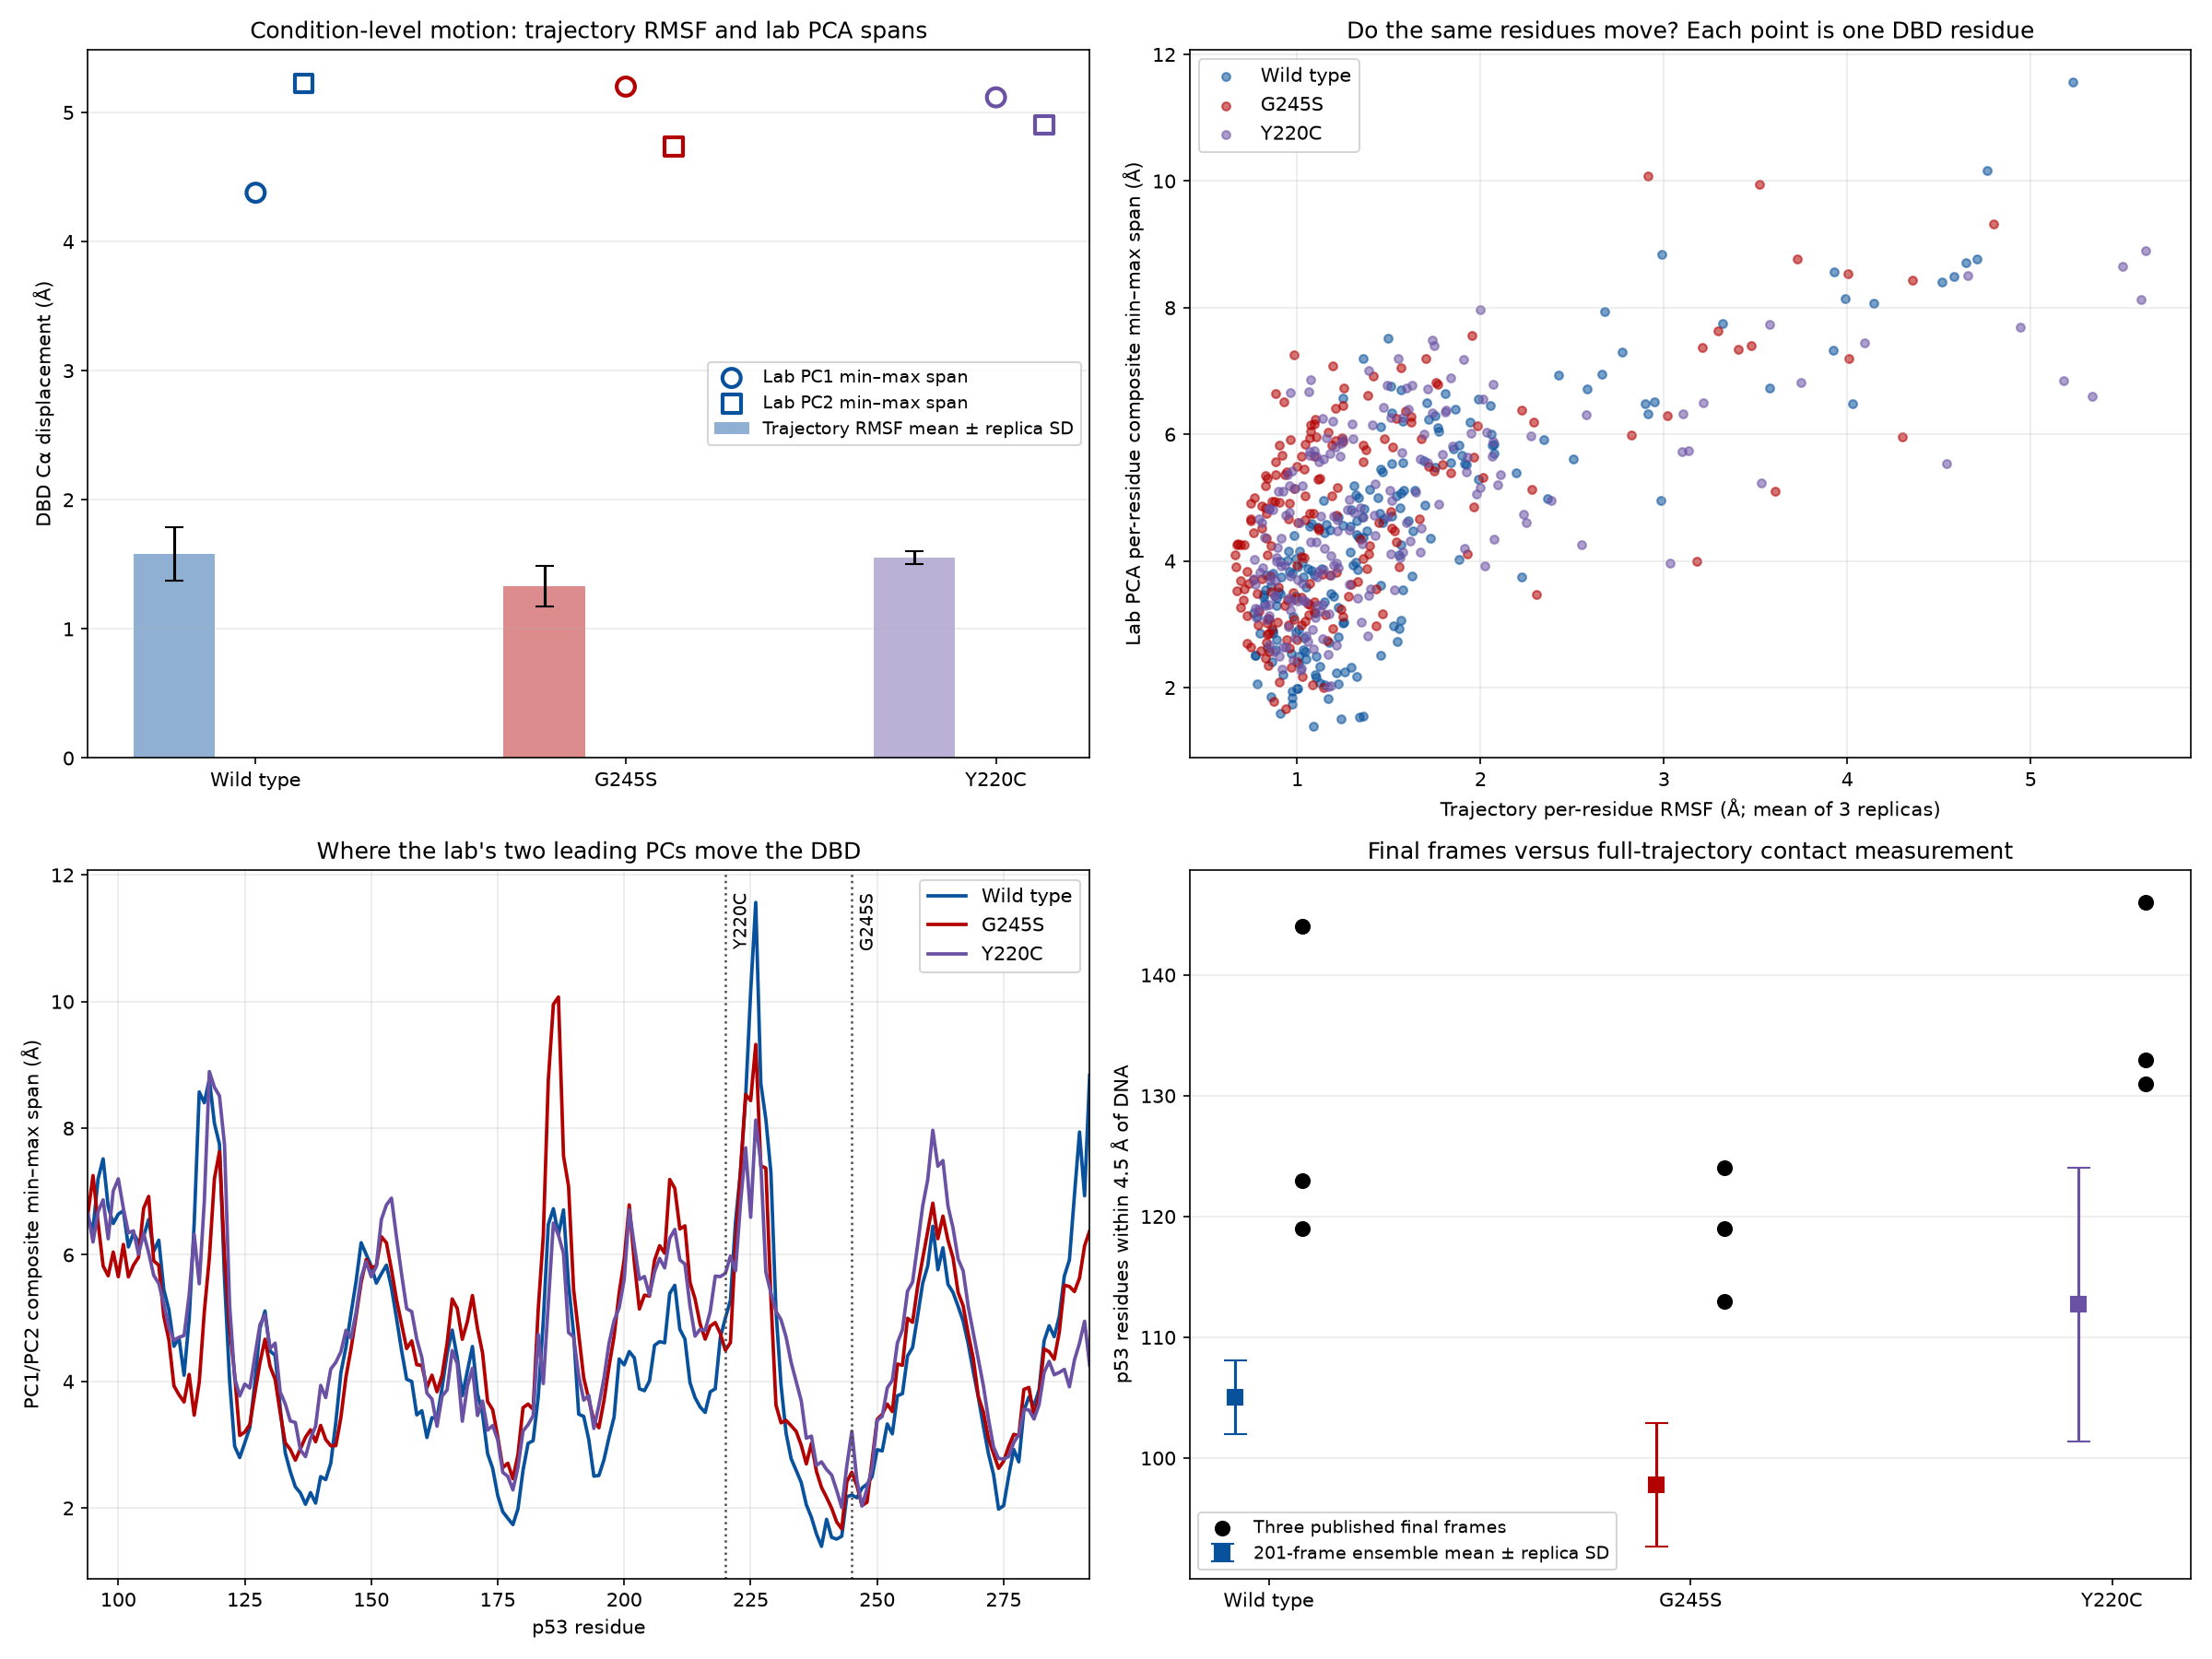

## Final assessment

### Where the lab products agree with our measurements

- **The same broad DBD regions are mobile** , particularly around residues 116–121 and 223–228.
- **Y220C is broadly WT-like at the domain level** .
- **G245S’s effect is distributed** , not centered on residue 245.
- **The endpoint contact ordering matches the trajectory ordering** : G245S below WT and Y220C above WT.
- **Mutant endpoint conformations are not separated from ordinary replica variation** .

### Where they do not agree

- **The PCA extremes do not show G245S as globally less mobile** . Its two-PC span is slightly larger than WT’s even though its replica-averaged RMSF is lower.
- **The exact collective modes are not WT-like** in either mutant; the leading two-PC subspaces overlap only moderately.
- **At residue 245, the PCA and RMSF changes have opposite signs** , although both agree it is not a major hotspot.
- **The final frames alone do not make the G245S contact reduction meaningful relative to replica spread** .
- **Final frames systematically overrepresent contact-rich conformations** , so they do not reproduce the absolute trajectory-average contact counts.

The most defensible combined interpretation is: **the lab’s PCA analysis validates the spatial pattern of DBD mobility and the nonlocal nature of the mutation effects, but it does not validate a simple condition-wide claim that G245S moves less. The condition differences are mode-dependent, and most are comparable to replica-to-replica variation.**

In [3]:
%%ask
The lab also published the extreme structures along their own principal components,
and the final frame of every run. Fetch those and tell me whether the motion you
measured agrees with what their own analysis shows.

Say clearly where it agrees and where it does not.

## What this run cost

Add up the megabytes reported above and compare them with 92 GB.

Nothing here required the data to be moved, mirrored or unpacked — only that it be
published file by file on a server that answers range requests. The Amaro Lab
already does that for this dataset and for the mucins collection. The other 44
datasets on their page are single `.tar.gz` archives, and gzip cannot be read from
the middle, so none of them can be queried this way until they are republished
unpacked.

That is the whole ask, and it is one they have already answered twice.